In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

In [2]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones y duraciones (en semanas) se adjunta. El jefe de proyecto sólo puede hacer seguimiento estrecho de cuatro actividades.

In [3]:
pregunta_1 = "1. Calcule el calendario del proyecto con sus holguras.  "
pregunta_2 = "2. Ordene las actividades de mayor a menor necesidad de vigilancia (primero las críticas; entre las demás, menor holgura total primero y, a igualdad, menor holgura libre). ¿Cuáles son las cuatro elegidas?  "
pregunta_3 = "3. ¿Qué actividades *no críticas* no pueden retrasarse ni una semana sin obligar a mover alguna sucesora? ¿Por qué no son críticas si no admiten retraso?  "
pregunta_4 = "4. ¿Qué actividad puede retrasarse más semanas sin que nadie lo note? ¿Cuántas?  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Calcule el calendario del proyecto con sus holguras.  

2. Ordene las actividades de mayor a menor necesidad de vigilancia (primero las críticas; entre las demás, menor holgura total primero y, a igualdad, menor holgura libre). ¿Cuáles son las cuatro elegidas?  

3. ¿Qué actividades *no críticas* no pueden retrasarse ni una semana sin obligar a mover alguna sucesora? ¿Por qué no son críticas si no admiten retraso?  

4. ¿Qué actividad puede retrasarse más semanas sin que nadie lo note? ¿Cuántas?  

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration
    ('A'     , '---'      , 6       ),
    ('B'     , '---'      , 3       ),
    ('C'     , '---'      , 2       ),
    ('D'     , 'B'        , 4       ),
    ('E'     , 'B'        , 8       ),
    ('F'     , 'A,B,C'    , 7       ),
    ('G'     , 'D,F'      , 8       ),
    ('H'     , 'G'        , 7       ),
    ('I'     , 'E'        , 6       ),
], columns=['activity', 'predecessor', 'duration']).set_index('activity')
datos_enunciado

,predecessor,duration
activity,,
A,---,6
B,---,3
C,---,2
D,B,4
E,B,8
F,"A,B,C",7
G,"D,F",8
H,G,7
I,E,6


El proyecto corresponde a la apertura de una clínica veterinaria; las actividades son las siguientes (las duraciones del cuadro están en semanas).

In [5]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'A': 'Estudio de mercado y local',
    'B': 'Proyecto de reforma y licencia',
    'C': 'Obra de reforma',
    'D': 'Instalación de quirófano y radiología',
    'E': 'Mobiliario y equipamiento clínico',
    'F': 'Software de gestión',
    'G': 'Selección de personal',
    'H': 'Acuerdos con proveedores',
    'I': 'Registro sanitario',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Estudio de mercado y local
B,Proyecto de reforma y licencia
C,Obra de reforma
D,Instalación de quirófano y radiología
E,Mobiliario y equipamiento clínico
F,Software de gestión
G,Selección de personal
H,Acuerdos con proveedores
I,Registro sanitario


# Resolución

In [6]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()

## Apartado 1

In [7]:
display(Markdown(pregunta_1))

1. Calcule el calendario del proyecto con sus holguras.  

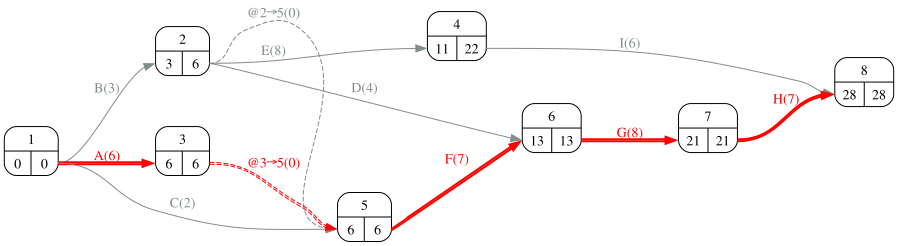

In [8]:
#| fig-cap: "Grafo PERT con tiempos y camino crítico"
#| label: fig-pert
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

In [9]:
#| tbl-cap: "Calendario y holguras"
#| label: tbl-calendario
calendario = proyecto.calendar(datos_proyecto['duration'])
calendario

,inicio_mas_temprano,inicio_mas_tardio,fin_mas_temprano,fin_mas_tardio,H_libre,H_independiente,H_total,duracion
activity,,,,,,,,
A,0,0,6,6,0,0,0,6
B,0,3,3,6,0,0,3,3
C,0,4,2,6,4,4,4,2
D,3,9,7,13,6,3,6,4
E,3,14,11,22,0,0,11,8
F,6,6,13,13,0,0,0,7
G,13,13,21,21,0,0,0,8
H,21,21,28,28,0,0,0,7
I,11,22,17,28,11,0,11,6


## Apartado 2

In [10]:
display(Markdown(pregunta_2))

2. Ordene las actividades de mayor a menor necesidad de vigilancia (primero las críticas; entre las demás, menor holgura total primero y, a igualdad, menor holgura libre). ¿Cuáles son las cuatro elegidas?  

In [11]:
#| tbl-cap: "Actividades ordenadas por necesidad de vigilancia"
#| label: tbl-orden
orden = calendario.sort_values(['H_total', 'H_libre', 'duracion'], ascending=[True, True, False])
orden['prioridad'] = range(1, len(orden) + 1)
orden[['prioridad', 'H_total', 'H_libre', 'H_independiente', 'duracion']]

,prioridad,H_total,H_libre,H_independiente,duracion
activity,,,,,
G,1,0,0,0,8
F,2,0,0,0,7
H,3,0,0,0,7
A,4,0,0,0,6
B,5,3,0,0,3
C,6,4,4,4,2
D,7,6,6,3,4
E,8,11,0,0,8
I,9,11,11,0,6


In [12]:
Markdown(f'Las cuatro actividades a vigilar son **{", ".join(orden.index[:4])}**. '
         'Si hay más de cuatro críticas, el criterio de desempate es la duración (una actividad larga tiene más ocasiones de retrasarse).')

Las cuatro actividades a vigilar son **G, F, H, A**. Si hay más de cuatro críticas, el criterio de desempate es la duración (una actividad larga tiene más ocasiones de retrasarse).

## Apartado 3

In [13]:
display(Markdown(pregunta_3))

3. ¿Qué actividades *no críticas* no pueden retrasarse ni una semana sin obligar a mover alguna sucesora? ¿Por qué no son críticas si no admiten retraso?  

In [14]:
sin_margen = calendario.index[(calendario['H_total'] > 0) & (calendario['H_libre'] == 0)].tolist()
Markdown(f'''Las actividades {", ".join(sin_margen)} tienen holgura libre cero pero holgura total positiva: cualquier retraso suyo mueve el inicio más temprano de una sucesora, pero esa sucesora tiene margen suficiente para absorberlo sin que el proyecto se alargue. No son críticas porque el plazo no depende de ellas; lo que no admiten es retrasarse sin molestar.''')

Las actividades B, E tienen holgura libre cero pero holgura total positiva: cualquier retraso suyo mueve el inicio más temprano de una sucesora, pero esa sucesora tiene margen suficiente para absorberlo sin que el proyecto se alargue. No son críticas porque el plazo no depende de ellas; lo que no admiten es retrasarse sin molestar.

## Apartado 4

In [15]:
display(Markdown(pregunta_4))

4. ¿Qué actividad puede retrasarse más semanas sin que nadie lo note? ¿Cuántas?  

In [16]:
mas_libre = calendario['H_libre'].idxmax()
Markdown(f'{mas_libre} puede retrasarse hasta {int(calendario.loc[mas_libre, "H_libre"])} semanas sin mover a ninguna otra actividad ni al plazo (su holgura libre).')

I puede retrasarse hasta 11 semanas sin mover a ninguna otra actividad ni al plazo (su holgura libre).